# pandas: Series and DataFrames, from basic to advanced

The previous block computed with NumPy arrays: fast, but one type per array and positions instead of names. Real data are **tables**: columns with names and different types (district as text, price as a number, last review as a date), and rows that each describe one thing. **pandas** builds such tables on top of NumPy. After this block you can load a table, select rows and columns, create and transform columns, summarise with `groupby` and pivot tables, combine tables with `merge` and `concat`, write the steps as one readable chain, and check code that an AI assistant wrote for you.

All examples use the Berlin Airbnb listings (Inside Airbnb, snapshot of 26 June 2026) and the monthly review counts of the same snapshot; the depth parts add small toy tables and two textbook datasets.

## Teaching map

The **core path** for the 45-minute lecture is every `##` section below, without the subsections marked *(depth: self-study or if time allows)*. The depth subsections go through the downloaded textbook chapters in full detail, for self-study or for a faster class.

| Section (core path) | Minutes | What it delivers |
|---|---|---|
| Series and DataFrame: index, columns and `dtype`; reading a file | 6 | the two pandas types, alignment, reading Parquet and CSV |
| Selecting rows and columns with `loc`, `iloc` and Boolean masks; missing values | 8 | labels versus positions, masks, `isna`, the short-stay population |
| Creating and transforming columns | 7 | `assign`, `.str`, `.dt`, `map`, `apply`, Copy-on-Write |
| Sorting, `value_counts`, `groupby` with `agg`, and pivot tables | 9 | split-apply-combine, named aggregation, `transform`, `pivot_table` |
| Combining tables with `merge` and `concat` | 6 | keys, `how`, `validate`, `indicator` |
| Method chaining, and tips for using AI coding assistants | 4 | one readable chain; how to check generated code |
| Worked example · Five questions about Berlin | 5 | hosts, districts, room types, prices, reviews |
| **Total** | **45** | then the exercises (30) and the debrief (15) |

```mermaid
flowchart LR
  S["Series and DataFrame<br/>index, columns, dtype"] --> Q["Select<br/>loc, iloc, masks,<br/>missing values"]
  Q --> T["Transform<br/>arithmetic, .str, .dt,<br/>map, apply"]
  T --> G["Summarise<br/>sort, value_counts,<br/>groupby, pivot_table"]
  G --> M["Combine<br/>merge, concat"]
  M --> K["Method chaining<br/>and checking AI code"]
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

The next cell imports the three packages of this block under their conventional names: NumPy as `np`, pandas as `pd` and matplotlib's plotting interface as `plt`.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("pandas", pd.__version__)

pandas 3.0.6


## Series and DataFrame: index, columns and `dtype`; reading a file

pandas has two main types:

- A **Series** is one column: a NumPy-like array of values with one `dtype`, plus an **index** of labels, one per value.
- A **DataFrame** is a table: several Series that share the same index, one per **column**. Each column has its own `dtype`.

Think of a spreadsheet in which the row numbers on the left are not fixed positions but name tags that stay with their row. The index is what NumPy does not have: rows keep their labels when you filter or sort, and two Series are aligned by label, not by position, when you combine them.

A list of dictionaries, one per record, becomes a DataFrame directly with `pd.DataFrame(records)`. The next cell turns the three invented listings of the previous block into a table and prints the `dtype` of each column with `.dtypes`.

In [3]:
records = [
    {"district": "Pankow", "nightly_price": 75, "available": True},
    {"district": "Mitte", "nightly_price": 90, "available": False},
    {"district": "Neukölln", "nightly_price": None, "available": True},
]
small = pd.DataFrame(records)
print(small.dtypes)
small

district             str
nightly_price    float64
available           bool
dtype: object


,district,nightly_price,available
0,Pankow,75.0,True
1,Mitte,90.0,False
2,Neukölln,NaN,True


Selecting one column with `df["name"]` gives a Series. The next cell shows its type, its index (`.index`) and its values as a NumPy array (`.to_numpy()`).

In [4]:
price = small["nightly_price"]          # one column: a Series
print(type(price).__name__, price.dtype)
print(price.index.tolist(), price.to_numpy())

Series float64
[0, 1, 2] [75. 90. nan]


The missing price became `NaN` and the column `float64`, as in NumPy. Text columns have the dtype `str` in pandas 3 (older versions showed `object`).

**Alignment by label.** When two Series are combined, pandas matches their labels, not their positions. The next cell adds the reviews of two years per district. **Predict** the result for Mitte, which has no value in 2025, before you run it. `.add(other, fill_value=0)` treats a missing label as 0 instead.

In [5]:
reviews_2024 = pd.Series({"Mitte": 10, "Pankow": 4})
reviews_2025 = pd.Series({"Pankow": 6, "Spandau": 1})
print(reviews_2024 + reviews_2025)
print(reviews_2024.add(reviews_2025, fill_value=0))

Mitte       NaN
Pankow     10.0
Spandau     NaN
dtype: float64
Mitte      10.0
Pankow     10.0
Spandau     1.0
dtype: float64


**Reading a file.** `pd.read_csv`, `pd.read_excel`, `pd.read_json` and `pd.read_parquet` turn a file into a DataFrame. Parquet stores the column types with the data, so dates arrive as dates and numbers as numbers. A CSV file is plain text, and pandas guesses the types: give `sep=";"` and `decimal=","` for German Excel exports, `dtype={"postal_code": str}` for identifiers with leading zeros, and `parse_dates=[...]` for dates.

**Before calculating, define what one row is.** Here one row is one listing in the snapshot, not a booking, a host or a flat. The next cell reads the listings, prints the number of rows and columns (`.shape`) and how many columns have each type, and shows the first rows of seven columns with `.head()`.

In [6]:
listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
print(listings.shape)                         # (rows, columns)
print(listings.dtypes.value_counts())         # how many columns of each type
listings[["id", "district", "room_type", "accommodates", "price", "minimum_nights", "last_review"]].head()

(12776, 42)
float64           19
int64             10
str                8
datetime64[ns]     3
object             2
Name: count, dtype: int64


,id,district,room_type,accommodates,price,minimum_nights,last_review
0,3176,Pankow,Entire home/apt,2,160.71,2.0,2025-08-09
1,9991,Pankow,Entire home/apt,7,193.33,6.0,2020-01-04
2,14325,Pankow,Entire home/apt,1,NaN,180.0,2023-11-30
3,17904,Friedrichshain-Kreuzberg,Entire home/apt,2,10.88,93.0,2026-05-31
4,20858,Pankow,Entire home/apt,4,372.67,3.0,2026-05-29


`head()` shows the first rows, `listings.info()` the columns with their types and the number of values present, `listings.describe()` summary statistics of the numeric columns. The index is `0, 1, 2, ...` (a `RangeIndex`); `set_index("id")` would make the listing id the row label.

> **In practice.** Check `shape` and `dtypes` right after reading a file. A numeric column read as `str` or a date read as text is the most common reason why a later step fails or, worse, gives a wrong answer silently.

### pandas step by step on small examples (depth: self-study or if time allows)

*Adapted from [Data Science for Beginners, lesson "Working with Data: Python and the Pandas Library"](https://github.com/microsoft/Data-Science-For-Beginners/blob/main/2-Working-With-Data/07-python/notebook.ipynb) (Microsoft, MIT licence). The unchanged original is [extras/12-pandas-introduction.ipynb](extras/12-pandas-introduction.ipynb); text and code are edited for current pandas.*

#### Series

A Series is like a list or a one-dimensional array, but with an index, and all operations are aligned by the index. The next cell creates one Series of numbers with the default index `0, 1, 2, ...` and one of words with an explicit index.

In [7]:
a = pd.Series(range(1, 10))
b = pd.Series(["I", "like", "to", "use", "Python", "and", "Pandas", "very", "much"], index=range(0, 9))
print(a.head(3))
print(b.head(3))

0    1
1    2
2    3
dtype: int64
0       I
1    like
2      to
dtype: str


A frequent use of Series is the **time series**: the index is a range of dates or times, created with `pd.date_range`. Suppose a shop records the number of items sold every day of 2020. The next cell simulates these sales with random numbers and plots them with the Series method `.plot()`.

Length of index is 366


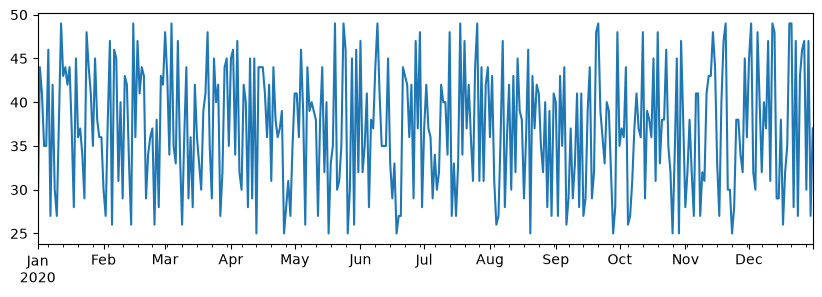

In [8]:
start_date = "2020-01-01"
end_date = "2020-12-31"
idx = pd.date_range(start_date, end_date)
print(f"Length of index is {len(idx)}")
items_sold = pd.Series(np.random.default_rng(42).integers(25, 50, size=len(idx)), index=idx)
items_sold.plot(figsize=(10, 3))
plt.show()

Every Sunday the shop owner also takes 10 items for herself. That is a second Series with one value per week (`freq="W"` gives the Sundays). Adding the two Series aligns them by date. **Predict** what the sum shows for a Monday.

In [9]:
additional_items = pd.Series(10, index=pd.date_range(start_date, end_date, freq="W"))
total_items = items_sold + additional_items
total_items.head(8)

2020-01-01     NaN
2020-01-02     NaN
2020-01-03     NaN
2020-01-04     NaN
2020-01-05    45.0
2020-01-06     NaN
2020-01-07     NaN
2020-01-08     NaN
dtype: float64

Every day without an entry in the weekly Series is treated as missing (`NaN`), and adding `NaN` to a number gives `NaN`. To get the correct total, `add` with `fill_value=0` treats the missing days as 0:

2020-01-01    27.0
2020-01-02    44.0
2020-01-03    41.0
2020-01-04    35.0
2020-01-05    45.0
2020-01-06    46.0
2020-01-07    27.0
2020-01-08    42.0
dtype: float64


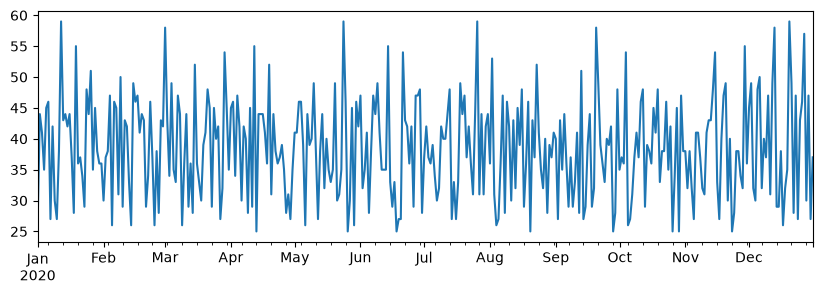

In [10]:
total_items = items_sold.add(additional_items, fill_value=0)
print(total_items.head(8))
total_items.plot(figsize=(10, 3))
plt.show()

A time series can be **resampled** to a coarser frequency. `resample("ME")` groups the days by month end, and `.mean()` gives the average daily sales per month. The next cell plots them as a bar chart with month names as labels.

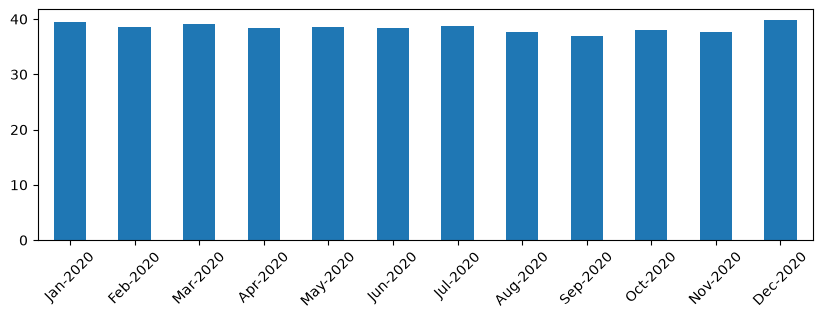

In [11]:
monthly = total_items.resample("ME").mean()
ax = monthly.plot(kind="bar", figsize=(10, 3))
ax.set_xticklabels([x.strftime("%b-%Y") for x in monthly.index], rotation=45)
plt.show()

#### DataFrame

A DataFrame is a collection of Series with the same index. A dictionary of Series becomes a DataFrame whose column names are the dictionary keys. The next cell combines the Series `a` and `b` from above into two columns `A` and `B`.

In [12]:
df = pd.DataFrame({"A": a, "B": b})
df.head()

,A,B
0,1,I
1,2,like
2,3,to
3,4,use
4,5,Python


Passing a *list* of Series instead makes each Series a **row**; `.T` (transpose) swaps rows and columns, and `rename` gives the columns names. The result is the same table as above.

In [13]:
pd.DataFrame([a, b]).T.rename(columns={0: "A", 1: "B"}).head()

,A,B
0,1,I
1,2,like
2,3,to
3,4,use
4,5,Python


**Selecting columns** works with one name (a Series) or a list of names (a DataFrame, in the order of the list):

In [14]:
print(df["A"].head(3))
df[["B", "A"]].head(3)

0    1
1    2
2    3
Name: A, dtype: int64


,B,A
0,I,1
1,like,2
2,to,3


**Selecting rows** by a condition: the expression `df["A"] < 5` returns a Boolean Series, and using it as an index keeps the rows where it is `True`.

In [15]:
df[df["A"] < 5]

,A,B
0,1,I
1,2,like
2,3,to
3,4,use


Because the condition is a whole Series, Python's `and` cannot combine two conditions: `df[df["A"] > 5 and df["A"] < 7]` raises an error. Use the element-wise `&` with parentheses around each condition:

In [16]:
df[(df["A"] > 5) & (df["A"] < 7)]

,A,B
5,6,and


**Creating new computed columns.** An expression on columns computes a new Series, and assigning it to a new name adds a column. The next cell computes how far each value of `A` lies from the mean of `A`.

In [17]:
df["DivA"] = df["A"] - df["A"].mean()
df.head()

,A,B,DivA
0,1,I,-4.0
1,2,like,-3.0
2,3,to,-2.0
3,4,use,-1.0
4,5,Python,0.0


Not every Python expression works on a whole column. `len(df["B"])` is the length of the *column* (9), not of each word, and `"Low" if df["A"] < 5 else "Hi"` raises an error, because a Series has no single truth value. To apply a function to every value, use `apply`:

In [18]:
print(len(df["B"]))                      # the number of rows, not what we want
df["LenB"] = df["B"].apply(len)          # the length of each word
df.head()

9


,A,B,DivA,LenB
0,1,I,-4.0,1
1,2,like,-3.0,4
2,3,to,-2.0,2
3,4,use,-1.0,3
4,5,Python,0.0,6


**Selecting rows by position** uses `iloc`, as in NumPy: `df.iloc[:5]` gives the first five rows.

In [19]:
df.iloc[:5]

,A,B,DivA,LenB
0,1,I,-4.0,1
1,2,like,-3.0,4
2,3,to,-2.0,2
3,4,use,-1.0,3
4,5,Python,0.0,6


**Grouping** gives a result similar to a pivot table in a spreadsheet. The next cell computes the mean of the numeric columns for each word length `LenB`; `numeric_only=True` skips the text column.

In [20]:
df.groupby(by="LenB").mean(numeric_only=True)

,A,DivA
LenB,,
1,1.000000,-4.000000
2,3.000000,-2.000000
3,5.000000,0.000000
4,6.333333,1.333333
6,6.000000,1.000000


`aggregate` (or `agg`) computes different summaries per column; here the number of rows in each group and the mean of `A`, renamed to readable column names:

In [21]:
(df.groupby(by="LenB")
   .aggregate({"DivA": len, "A": lambda x: x.mean()})
   .rename(columns={"DivA": "Count", "A": "Mean"}))

,Count,Mean
LenB,,
1,1,1.000000
2,1,3.000000
3,2,5.000000
4,3,6.333333
6,2,6.000000


**Printing and plotting.** `df.head()` shows the first rows, which is the quickest check that a step did what you meant. `.plot()` draws a column with matplotlib, and `kind=` chooses the chart type; Session 5 covers visualisation in detail.

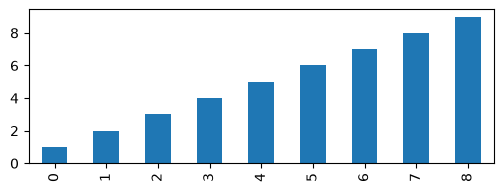

In [22]:
df["A"].plot(kind="bar", figsize=(6, 2))
plt.show()

> 📖 **Read more:** [extras/12-pandas-introduction.ipynb](extras/12-pandas-introduction.ipynb) (Microsoft, *Data Science for Beginners*): the original lesson, which continues with two real datasets; some of its calls need small changes for pandas 3.

## Selecting rows and columns with `loc`, `iloc` and Boolean masks; missing values

- `df["col"]` selects one column as a Series; `df[["a", "b"]]` (a list of names) a smaller DataFrame.
- `.loc[rows, columns]` selects by **labels**; `.iloc[rows, columns]` by **positions**, as in NumPy.
- A comparison on a column gives a Boolean Series, a **mask**. `df[mask]` or `df.loc[mask, columns]` keeps the rows where it is `True`. Combine masks with `&`, `|` and `~`, with parentheses around each comparison. `isin([...])` and `between(a, b)` save long chains of `|` and `&`.

The next cell uses all three: one value by label and by position, one listing by its id after `set_index("id")`, and two masks counted with `.sum()`.

In [23]:
district_pos = listings.columns.get_loc("district")
print(listings.loc[0, "district"], "|", listings.iloc[0, district_pos])   # label 0 / position of the district column

by_id = listings.set_index("id")
print(by_id.loc[3176, ["district", "room_type", "price"]].to_dict())

inner = listings["district"].isin(["Mitte", "Friedrichshain-Kreuzberg", "Pankow"])
for_four = listings["accommodates"].between(4, 6)                 # both ends included
print(inner.sum(), (inner & for_four).sum())

Pankow | Pankow
{'district': 'Pankow', 'room_type': 'Entire home/apt', 'price': 160.71}
7428 2254


**Labels survive filtering and sorting; positions do not.** After `sort_values`, `.iloc[0]` is the first row on the page, while `.loc[0]` is still the row whose label is 0, wherever it now stands. Mixing them up selects the wrong row without any error.

**Missing values.** pandas marks a missing value as `NaN` (or `NaT` for dates, `None` or `NaN` in text columns). Find them with `.isna()` and `.notna()`, never with `== None` or `== np.nan` (both are always `False` for `NaN`). `count()` counts the values that are present, `len()` counts rows. Summary methods such as `mean()` and `median()` skip missing values; arithmetic with them gives `NaN`. The next cell counts rows and prices, and lists the five columns with the largest share of missing values: `isna().mean()` is the share of `True` per column.

In [24]:
print(len(listings), listings["price"].count())
listings.isna().mean().sort_values(ascending=False).head(5).round(3)   # share missing, worst columns first

12776 8441


bathrooms                  0.521
beds                       0.490
price                      0.339
estimated_revenue_l365d    0.339
license                    0.311
dtype: float64

About a third of the listings have no price, and many can only be booked for months. As in the previous block, the course compares prices only for **short stays**: a price present and a minimum stay below 28 nights. The next cell builds this subset with a mask.

In [25]:
short = listings[listings["price"].notna() & (listings["minimum_nights"] < 28)]
print(len(short), "short-stay listings with a price")

6701 short-stay listings with a price


> **In practice.** Decide for each analysis what a missing value means. `dropna()` removes rows, `fillna(0)` claims a value: a missing price is not a price of €0, but a listing without a review row in a review table really has zero reviews. Write the decision next to the code.

### Selection in detail: Series and DataFrames as dictionaries and arrays (depth: self-study or if time allows)

*Code adapted from [Python Data Science Handbook, "Data Indexing and Selection"](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/03.02-Data-Indexing-and-Selection.ipynb) (Jake VanderPlas, code MIT licence; populations updated to the 2020 census in the book's current edition). The explanations are written for this course: the book's text is CC BY-NC-ND and may not be adapted. The unchanged original is [extras/13-pandas-indexing-and-selection.ipynb](extras/13-pandas-indexing-and-selection.ipynb).*

pandas selection makes sense once you see a Series in two ways at the same time: as a **dictionary** that maps labels to values, and as a **one-dimensional array** with positions. A DataFrame is likewise a dictionary of columns and a two-dimensional array. Most selection rules follow from these two views; the confusing cases are the ones where both views apply.

#### A Series as a dictionary

The next cell creates a Series with the labels `a` to `d` and looks up one value by its label, exactly as in a dictionary.

In [26]:
data = pd.Series([0.25, 0.5, 0.75, 1.0], index=["a", "b", "c", "d"])
print(data)
data["b"]

a    0.25
b    0.50
c    0.75
d    1.00
dtype: float64


np.float64(0.5)

The usual dictionary operations work: `in` tests for a label, `.keys()` returns the index, `.items()` the (label, value) pairs. Assigning to a new label adds an element, as with a dictionary.

In [27]:
print("a" in data)
print(data.keys())
print(list(data.items()))

data["e"] = 1.25
data

True
Index(['a', 'b', 'c', 'd'], dtype='str')
[('a', 0.25), ('b', 0.5), ('c', 0.75), ('d', 1.0)]


a    0.25
b    0.50
c    0.75
d    1.00
e    1.25
dtype: float64

#### A Series as an array

The array view adds slices, masks and lists of labels (*fancy indexing*). A slice with **labels** includes the end label; a slice with **positions** stops before the end, as in NumPy. **Predict** how many elements each of the first two lines returns.

In [28]:
print(data["a":"c"])                        # slice by labels: "c" is included
print(data.iloc[0:2])                       # slice by positions: 2 is excluded
print(data[(data > 0.3) & (data < 0.8)])    # mask
print(data[["a", "e"]])                     # list of labels

a    0.25
b    0.50
c    0.75
dtype: float64
a    0.25
b    0.50
dtype: float64
b    0.50
c    0.75
dtype: float64
a    0.25
e    1.25
dtype: float64


#### Why `loc` and `iloc` exist

The two views clash when the labels are themselves integers. Is `data[1]` the label 1 or the position 1? For a Series with an integer index, plain square brackets use the **label** for a single value but the **position** for a slice. The next cell shows both on a Series with the labels 1, 3 and 5.

In [29]:
data = pd.Series(["a", "b", "c"], index=[1, 3, 5])
print(data)
print(data[1])          # label 1
print(data[1:3])        # positions 1 and 2

1    a
3    b
5    c
dtype: str
a
3    b
5    c
dtype: str


To remove the guesswork, pandas offers two **indexers**. `loc` always uses labels; `iloc` always uses positions (the *i* stands for integer position). With them the same code means the same thing for every index. Python's motto "explicit is better than implicit" applies: in analysis code, prefer `loc` and `iloc` over plain brackets for rows.

In [30]:
print(data.loc[1])       # label 1
print(data.loc[1:3])     # labels 1 to 3, both included
print(data.iloc[1])      # position 1
print(data.iloc[1:3])    # positions 1 and 2

a
1    a
3    b
dtype: str
b
3    b
5    c
dtype: str


#### A DataFrame as a dictionary of columns

The next cell builds a table of five US states from two Series, area in square miles and population in the 2020 census, as a dictionary of columns.

In [31]:
area = pd.Series({"California": 423967, "Texas": 695662,
                  "Florida": 170312, "New York": 141297,
                  "Pennsylvania": 119280})
pop = pd.Series({"California": 39538223, "Texas": 29145505,
                 "Florida": 21538187, "New York": 20201249,
                 "Pennsylvania": 13002700})
data = pd.DataFrame({"area": area, "pop": pop})
data

,area,pop
California,423967,39538223
Texas,695662,29145505
Florida,170312,21538187
New York,141297,20201249
Pennsylvania,119280,13002700


A column is selected like a dictionary value, `data["area"]`. pandas also allows attribute access, `data.area`, which is shorter but fails when the column name is not a valid Python name or clashes with a DataFrame method. **Predict** the last line: DataFrames have a method called `pop`.

In [32]:
print(data["area"].equals(data.area))
print(data.pop is data["pop"])        # data.pop is the method, not the column

True
False


So use `data["col"]` in code you keep, and especially when you *assign* a column: `data["density"] = ...` creates a new column, while `data.density = ...` would only set an attribute. The next cell adds the population density.

In [33]:
data["density"] = data["pop"] / data["area"]
data

,area,pop,density
California,423967,39538223,93.257784
Texas,695662,29145505,41.896072
Florida,170312,21538187,126.463121
New York,141297,20201249,142.970120
Pennsylvania,119280,13002700,109.009893


#### A DataFrame as a two-dimensional array

`.values` (or `.to_numpy()`) gives the underlying NumPy array, and `.T` swaps rows and columns. On the array, `[0]` is the first *row*; on the DataFrame, `["area"]` is a *column*: the two views use the same brackets for different axes.

In [34]:
print(data.values)
print(data.values[0])
data.T

[[4.23967000e+05 3.95382230e+07 9.32577842e+01]
 [6.95662000e+05 2.91455050e+07 4.18960717e+01]
 [1.70312000e+05 2.15381870e+07 1.26463121e+02]
 [1.41297000e+05 2.02012490e+07 1.42970120e+02]
 [1.19280000e+05 1.30027000e+07 1.09009893e+02]]
[4.23967000e+05 3.95382230e+07 9.32577842e+01]


,California,Texas,Florida,New York,Pennsylvania
area,4.239670e+05,6.956620e+05,1.703120e+05,1.412970e+05,1.192800e+05
pop,3.953822e+07,2.914550e+07,2.153819e+07,2.020125e+07,1.300270e+07
density,9.325778e+01,4.189607e+01,1.264631e+02,1.429701e+02,1.090099e+02


For array-style selection of rows *and* columns, use the indexers. `iloc` takes positions and excludes the end; `loc` takes labels and includes the end; both accept masks and lists of names. The last line combines a mask on the rows with a list of columns: the states with more than 120 inhabitants per square mile.

In [35]:
print(data.iloc[:3, :2])
print(data.loc[:"Florida", :"pop"])
data.loc[data["density"] > 120, ["pop", "density"]]

              area       pop
California  423967  39538223
Texas       695662  29145505
Florida     170312  21538187
              area       pop
California  423967  39538223
Texas       695662  29145505
Florida     170312  21538187


,pop,density
Florida,21538187,126.463121
New York,20201249,142.970120


Indexers can also set values; the next cell overwrites one cell by position.

In [36]:
data.iloc[0, 2] = 90
data

,area,pop,density
California,423967,39538223,90.000000
Texas,695662,29145505,41.896072
Florida,170312,21538187,126.463121
New York,141297,20201249,142.970120
Pennsylvania,119280,13002700,109.009893


#### Two shortcuts that select rows

Plain brackets on a DataFrame select *columns*, with two exceptions that select *rows*: a slice (by labels or positions) and a Boolean mask.

In [37]:
print(data["Florida":"New York"])      # rows by label slice
print(data[1:3])                       # rows by position slice
data[data["density"] > 120]            # rows by mask

            area       pop     density
Florida   170312  21538187  126.463121
New York  141297  20201249  142.970120
           area       pop     density
Texas    695662  29145505   41.896072
Florida  170312  21538187  126.463121


,area,pop,density
Florida,170312,21538187,126.463121
New York,141297,20201249,142.970120


> **Note.** The shortcuts are common in tutorials and in AI-generated code. When you read `df[...]`, ask which of the three cases it is: a column name, a slice of rows or a mask. In your own code, `df.loc[...]` and `df.iloc[...]` make the intent visible.

> 📖 **Read more:** [extras/13-pandas-indexing-and-selection.ipynb](extras/13-pandas-indexing-and-selection.ipynb) (*Python Data Science Handbook*): the original chapter on selection in Series and DataFrames.

## Creating and transforming columns: vectorised arithmetic, `.str` and `.dt`, `map` and `apply`

New columns come from existing ones, mostly with vectorised operations as in NumPy. `df.assign(name=...)` returns a new table with the column added; `df["name"] = ...` adds it in place.

- **Arithmetic** works element by element and aligned by the index.
- **`.str`** applies string methods to every value of a text column: `lower`, `contains`, `startswith`, `replace`, `split`, `len`, regular expressions with `match` and `extract`.
- **`.dt`** gives the parts of a date column: `year`, `month`, `dayofweek`, `day_name()`; subtracting two dates gives a duration, whose `.dt.days` is a number.
- **`map`** replaces each value by looking it up in a dictionary (or by applying a function to it).
- **`apply`** runs a Python function on every row or every value. It is flexible but slow, because it is a Python loop: use it only when no vectorised method exists.

The next cell adds five columns to the short stays in one `assign`, one per kind of transformation.

In [38]:
snapshot = pd.Timestamp("2026-06-26")
short_labels = {"Entire home/apt": "entire", "Private room": "private",
                "Shared room": "shared", "Hotel room": "hotel"}

short = short.assign(
    price_per_guest=short["price"] / short["accommodates"],                       # arithmetic
    balcony=short["name"].str.contains("balcony|balkon", case=False),             # .str, with a regular expression
    review_year=short["last_review"].dt.year,                                     # .dt
    days_since_review=(snapshot - short["last_review"]).dt.days,                  # a duration in days
    room=short["room_type"].map(short_labels),                                    # map with a dictionary
)
short[["name", "room", "accommodates", "price", "price_per_guest", "balcony", "review_year", "days_since_review"]].head()

,name,room,accommodates,price,price_per_guest,balcony,review_year,days_since_review
0,Fabulous Flat in great Location,entire,2,160.71,80.355000,False,2025.0,321.0
1,Geourgeous flat - outstanding views,entire,7,193.33,27.618571,False,2020.0,2365.0
4,Designer Loft in Berlin Mitte,entire,4,372.67,93.167500,False,2026.0,28.0
6,"""Prenzel Garten"" mit Terrasse",entire,5,243.50,48.700000,False,2026.0,4.0
8,PEACEFUL FLAT WITH VINTAGE TOUCH IN PRENZLAUER...,entire,8,212.50,26.562500,False,2026.0,1.0


The next cell summarises three of the new columns: the share of titles that mention a balcony (the mean of a Boolean column), the median price per guest, and how many listings had their last review in each of the last three years.

In [39]:
print(short["balcony"].mean().round(3), "of the short-stay titles mention a balcony")
print(short["price_per_guest"].median(), "median price per guest and night")
print(short["review_year"].value_counts().sort_index().tail(3))

0.051 of the short-stay titles mention a balcony
52.25 median price per guest and night
review_year
2024.0     191
2025.0     615
2026.0    5319
Name: count, dtype: int64


`apply` with `axis=1` passes one row at a time to a function. The rule below gives a rough "size class"; it could be written without `apply` (with `np.select` or `pd.cut`, see the depth part below), and on large tables it should be.

In [40]:
def size_class(row):
    """Classify a listing by room type and number of guests."""
    if row["room_type"] != "Entire home/apt":
        return "room"
    return "large flat" if row["accommodates"] >= 4 else "small flat"


short["size_class"] = short.apply(size_class, axis=1)
short["size_class"].value_counts()

size_class
large flat    2645
small flat    2043
room          2013
Name: count, dtype: int64

> **In practice.** pandas 3 uses *Copy-on-Write*: a filtered table such as `short` behaves as an independent copy, and changing it never changes `listings`. To change some rows of a column, select rows and column in one step: `df.loc[mask, "col"] = value`. A chained form such as `df[mask]["col"] = value` changes a temporary copy and has no effect.

### More ways to create columns (depth: self-study or if time allows)

**Bins with `pd.cut`.** `pd.cut(values, bins, labels)` puts numbers into intervals, such as price bands. The `bins` are the edges; by default each interval includes its right edge, so `(100, 200]` contains 200 but not 100. `np.inf` is an open upper end. The next cell counts the short stays per price band.

In [41]:
bands = pd.cut(short["price"], bins=[0, 100, 200, 500, np.inf],
               labels=["up to 100", "100-200", "200-500", "over 500"])
bands.value_counts().sort_index()

price
up to 100    1433
100-200      3025
200-500      2063
over 500      180
Name: count, dtype: int64

**Conditions without `apply`.** `np.where(condition, if_true, if_false)` chooses between two values element by element; `np.select([cond1, cond2, ...], [value1, value2, ...], default=...)` between several, taking the first condition that is `True`. The next cell rebuilds the size class of the `apply` example with `np.select` and checks that both give the same result.

In [42]:
conditions = [short["room_type"] != "Entire home/apt", short["accommodates"] >= 4]
size_fast = np.select(conditions, ["room", "large flat"], default="small flat")
print((size_fast == short["size_class"]).all())

short["superhost_label"] = np.where(short["host_is_superhost"] == True, "superhost", "other")
short["superhost_label"].value_counts()

True


superhost_label
other        3860
superhost    2841
Name: count, dtype: int64

**More text and date methods.** `.str.split()` cuts a text into a list of words and `.str.len()` counts the elements; `.str.lower()` makes comparisons independent of case. `.dt.day_name()` and `.dt.month` give the weekday and the month of a date. The next cell computes the number of words in each title and the weekday of the last review.

In [43]:
title_words = short["name"].str.split().str.len()
print(title_words.describe().round(1))
short["last_review"].dt.day_name().value_counts().head(3)

count    6701.0
mean        5.7
std         2.0
min         1.0
25%         4.0
50%         6.0
75%         7.0
max        28.0
Name: name, dtype: float64


last_review
Sunday    1797
Monday    1088
Friday     749
Name: count, dtype: int64

**Types and names.** `astype` converts a column to another type, for example `"category"` for a text column with few distinct values (it saves memory and keeps a fixed order); `rename(columns={...})` gives columns new names.

In [44]:
room_cat = short["room_type"].astype("category")
print(room_cat.cat.categories.tolist())
short[["price", "accommodates"]].rename(columns={"price": "price_eur", "accommodates": "guests"}).head(3)

['Entire home/apt', 'Hotel room', 'Private room', 'Shared room']


,price_eur,guests
0,160.71,2
1,193.33,7
4,372.67,4


## Sorting, `value_counts`, `groupby` with `agg`, and pivot tables

**Sorting and counting.** `sort_values` sorts by one or more columns (`ascending=False` from the largest); `nlargest(n, "col")` is a shortcut. `value_counts()` counts the categories of a column, `normalize=True` gives shares. The next cell shows the three most expensive short stays and the share of each room type among all listings.

In [45]:
print(short.nlargest(3, "price")[["district", "room_type", "accommodates", "price"]])
listings["room_type"].value_counts(normalize=True).round(3)

                    district        room_type  accommodates    price
8434   Steglitz - Zehlendorf  Entire home/apt             7  10025.0
12710                Spandau  Entire home/apt             5   7999.2
9515      Treptow - Köpenick  Entire home/apt            16   4458.0


room_type
Entire home/apt    0.692
Private room       0.294
Hotel room         0.007
Shared room        0.007
Name: proportion, dtype: float64

**`groupby`.** Most questions are "per something": per district, per room type, per host. `groupby` **splits** the rows into groups by the values of one or more columns, **applies** a summary to each group and **combines** the results into a new table, the *split-apply-combine* pattern.

```mermaid
flowchart LR
  T["short stays<br/>one row per listing"] -->|"split by district"| G1["Mitte rows"]
  T --> G2["Pankow rows"]
  T --> G3["... 12 groups"]
  G1 -->|"apply: median price"| R1["one number"]
  G2 -->|"apply: median price"| R2["one number"]
  G3 -->|"apply"| R3["..."]
  R1 --> C["combine: one row per district"]
  R2 --> C
  R3 --> C
```

`agg` computes several summaries at once. With **named aggregation**, `new_name=("column", "function")`, the result has readable column names. The next cell summarises the short stays per district and sorts by the median price.

In [46]:
by_district = (
    short.groupby("district")
    .agg(listings=("id", "size"),
         median_price=("price", "median"),
         median_per_guest=("price_per_guest", "median"),
         share_balcony=("balcony", "mean"))
    .sort_values("median_price", ascending=False)
    .round(2)
)
by_district

,listings,median_price,median_per_guest,share_balcony
district,,,,
Mitte,1537,187.00,58.14,0.05
Pankow,1033,174.00,53.25,0.07
Friedrichshain-Kreuzberg,1337,160.00,53.38,0.04
Charlottenburg-Wilm.,760,149.30,53.88,0.05
Tempelhof - Schöneberg,478,137.25,47.85,0.04
Lichtenberg,226,132.00,47.00,0.07
Steglitz - Zehlendorf,174,130.62,46.73,0.03
Neukölln,556,130.00,50.50,0.08
Spandau,105,126.50,49.08,0.01


Mitte is the most expensive district for a night (median €187), Reinickendorf the cheapest (€99.54). The **median** is reported because prices are skewed: 25 short-stay listings ask for more than €1,000 a night and pull the mean (€194) far above the typical price.

![Price distributions of short-stay listings by room type, with mean and median marked](../figures/price_by_room_type.png)

**`transform`: one value per row.** `agg` returns one row per group; `transform` returns one value per *original* row, the group's summary repeated for every member. That is what you need to compare each listing with its own district. **Predict** the length of the result before running the next cell.

In [47]:
district_median = short.groupby("district")["price"].transform("median")
print(len(short), len(district_median))
short.assign(district_median=district_median,
             vs_district=(short["price"] / district_median).round(2))[
    ["district", "price", "district_median", "vs_district"]].head()

6701 6701


,district,price,district_median,vs_district
0,Pankow,160.71,174.0,0.92
1,Pankow,193.33,174.0,1.11
4,Pankow,372.67,174.0,2.14
6,Mitte,243.50,187.0,1.30
8,Pankow,212.50,174.0,1.22


**Pivot tables.** A `groupby` over two columns gives a long table with one row per combination. `pivot_table` spreads one of the grouping columns across the columns, which is easier to read: rows by district, columns by room type, cells the median price. `margins=True` adds the totals over all rows and columns. The next cell builds it for the two common room types.

In [48]:
two_types = short[short["room_type"].isin(["Entire home/apt", "Private room"])]
prices_table = two_types.pivot_table(index="district", columns="room_type", values="price",
                                     aggfunc="median", margins=True, margins_name="All")
prices_table.round(0)

room_type,Entire home/apt,Private room,All
district,,,
Charlottenburg-Wilm.,180.0,103.0,149.0
Friedrichshain-Kreuzberg,187.0,100.0,162.0
Lichtenberg,164.0,81.0,133.0
Marzahn - Hellersdorf,142.0,74.0,126.0
Mitte,212.0,117.0,192.0
Neukölln,160.0,93.0,132.0
Pankow,198.0,98.0,174.0
Reinickendorf,121.0,74.0,100.0
Spandau,168.0,80.0,124.0


In every district an entire home costs between 1.6 and 2.1 times as much as a private room. The `All` row is the median over all districts (€185 and €97), not the mean of the twelve district medians. With all four room types, cells for combinations without a listing would be `NaN`: `aggfunc="size"` shows how many rows stand behind each cell, which you should check before trusting a median of a handful of listings.

![Listing counts and median short-stay prices by district](../figures/listings_by_district.png)

### Grouping in depth: aggregate, filter, transform and apply (depth: self-study or if time allows)

*Code adapted from [Python Data Science Handbook, "Aggregation and Grouping"](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/03.08-Aggregation-and-Grouping.ipynb) (Jake VanderPlas, code MIT licence); explanations written for this course. The unchanged original is [extras/14-pandas-groupby.ipynb](extras/14-pandas-groupby.ipynb). The planets data are the seaborn example dataset, bundled in [extras/data/planets.csv](extras/data/planets.csv).*

This part uses a dataset from astronomy: the planets discovered around other stars up to 2014, one row per planet, with the discovery method, the orbital period (days), the mass (in Jupiter masses), the distance (light years) and the year of discovery. It is small and has several categories, which makes grouping easy to see. The next cell reads it.

In [49]:
planets = pd.read_csv("sessions/01-careers-and-python/workbooks/extras/data/planets.csv")
print(planets.shape)
planets.head()

(1035, 6)


,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009


#### Simple aggregations

On a Series, an aggregation returns one number. On a DataFrame, it returns one number **per column**; `axis="columns"` aggregates along each row instead. The next cell shows both on a small random table.

In [50]:
rng = np.random.default_rng(42)
ser = pd.Series(rng.random(5))
print(ser.sum(), ser.mean())

df = pd.DataFrame({"A": rng.random(5), "B": rng.random(5)})
print(df.mean())
print(df.mean(axis="columns"))

2.8629777851664118 0.5725955570332824
A    0.620265
B    0.641521
dtype: float64
0    0.673210
1    0.843952
2    0.714965
3    0.475438
4    0.446900
dtype: float64


`describe()` computes the common aggregations for every numeric column at once. Here it runs on the planets with no missing value (`dropna()`). The table shows, for example, that half of these planets were discovered in 2009 or later.

In [51]:
planets.dropna().describe()

,number,orbital_period,mass,distance,year
count,498.00000,498.000000,498.000000,498.000000,498.000000
mean,1.73494,835.778671,2.509320,52.068213,2007.377510
std,1.17572,1469.128259,3.636274,46.596041,4.167284
min,1.00000,1.328300,0.003600,1.350000,1989.000000
25%,1.00000,38.272250,0.212500,24.497500,2005.000000
50%,1.00000,357.000000,1.245000,39.940000,2009.000000
75%,2.00000,999.600000,2.867500,59.332500,2011.000000
max,6.00000,17337.500000,25.000000,354.000000,2014.000000


The built-in aggregations of Series and DataFrame:

| Aggregation | Returns |
|---|---|
| `count` | number of values present (not missing) |
| `first`, `last` | first and last value |
| `mean`, `median` | mean and median |
| `min`, `max` | smallest and largest value |
| `std`, `var` | standard deviation and variance |
| `prod`, `sum` | product and sum |
| `nunique` | number of distinct values |
| `size` (on a group) | number of rows, missing values included |

#### Split, apply, combine on a toy table

To see exactly what `groupby` does, take a table with six rows and three keys. `groupby("key")` alone computes nothing: it returns a `DataFrameGroupBy` object that knows which rows belong to which key and waits for a summary. pandas then computes the summary for all groups in one pass, without building the separate group tables.

In [52]:
df = pd.DataFrame({"key": ["A", "B", "C", "A", "B", "C"],
                   "data": range(6)}, columns=["key", "data"])
print(df.groupby("key"))
df.groupby("key").sum()

,data
key,
A,3
B,5
C,7


#### Selecting a column, iterating, dispatching

Selecting a column of the grouped object gives a `SeriesGroupBy`; nothing is computed until you ask for a summary. The next cell takes the median orbital period per discovery method.

In [53]:
planets.groupby("method")["orbital_period"].median()

method
Astrometry                         631.180000
Eclipse Timing Variations         4343.500000
Imaging                          27500.000000
Microlensing                      3300.000000
Orbital Brightness Modulation        0.342887
Pulsar Timing                       66.541900
Pulsation Timing Variations       1170.000000
Radial Velocity                    360.200000
Transit                              5.714932
Transit Timing Variations           57.011000
Name: orbital_period, dtype: float64

A grouped object can be looped over: each step gives the key and the sub-table of that group. This is useful for checking, but slower than the built-in summaries.

In [54]:
for (method, group) in planets.groupby("method"):
    print(f"{method:30s} shape={group.shape}")

Astrometry                     shape=(2, 6)
Eclipse Timing Variations      shape=(9, 6)
Imaging                        shape=(38, 6)
Microlensing                   shape=(23, 6)
Orbital Brightness Modulation  shape=(3, 6)
Pulsar Timing                  shape=(5, 6)
Pulsation Timing Variations    shape=(1, 6)
Radial Velocity                shape=(553, 6)
Transit                        shape=(397, 6)
Transit Timing Variations      shape=(4, 6)


Any method of a Series can be called on a grouped column and is then applied to every group: `describe()` gives one row of statistics per method. The table shows when each method was first used: most planets were found by radial velocity and, more recently, by the transit method.

In [55]:
planets.groupby("method")["year"].describe()

,count,mean,std,min,25%,50%,75%,max
method,,,,,,,,
Astrometry,2.0,2011.500000,2.121320,2010.0,2010.75,2011.5,2012.25,2013.0
Eclipse Timing Variations,9.0,2010.000000,1.414214,2008.0,2009.00,2010.0,2011.00,2012.0
Imaging,38.0,2009.131579,2.781901,2004.0,2008.00,2009.0,2011.00,2013.0
Microlensing,23.0,2009.782609,2.859697,2004.0,2008.00,2010.0,2012.00,2013.0
Orbital Brightness Modulation,3.0,2011.666667,1.154701,2011.0,2011.00,2011.0,2012.00,2013.0
Pulsar Timing,5.0,1998.400000,8.384510,1992.0,1992.00,1994.0,2003.00,2011.0
Pulsation Timing Variations,1.0,2007.000000,NaN,2007.0,2007.00,2007.0,2007.00,2007.0
Radial Velocity,553.0,2007.518987,4.249052,1989.0,2005.00,2009.0,2011.00,2014.0
Transit,397.0,2011.236776,2.077867,2002.0,2010.00,2012.0,2013.00,2014.0


#### Aggregate, filter, transform, apply

Beyond one summary per group, a grouped object has four general operations. The next cell creates a toy table with two numeric columns to show them.

In [56]:
rng = np.random.default_rng(0)
df = pd.DataFrame({"key": ["A", "B", "C", "A", "B", "C"],
                   "data1": range(6),
                   "data2": rng.integers(0, 10, 6)},
                  columns=["key", "data1", "data2"])
df

,key,data1,data2
0,A,0,8
1,B,1,6
2,C,2,5
3,A,3,2
4,B,4,3
5,C,5,0


**`aggregate`** (short `agg`) takes a list of functions, applied to every column, or a dictionary that assigns a function to each column.

In [57]:
print(df.groupby("key").aggregate(["min", "median", "max"]))
df.groupby("key").aggregate({"data1": "min", "data2": "max"})

    data1            data2           
      min median max   min median max
key                                  
A       0    1.5   3     2    5.0   8
B       1    2.5   4     3    4.5   6
C       2    3.5   5     0    2.5   5


,data1,data2
key,,
A,0,8
B,1,6
C,2,5


**`filter`** keeps or drops whole groups depending on a condition computed on the group. The function receives the sub-table of a group and returns `True` or `False`. The next cell keeps the groups whose `data2` values have a standard deviation above 4; it returns the original rows of those groups.

In [58]:
def filter_func(x):
    return x["data2"].std() > 4

print(df.groupby("key")[["data1", "data2"]].std())
df.groupby("key").filter(filter_func)

       data1     data2
key                   
A    2.12132  4.242641
B    2.12132  2.121320
C    2.12132  3.535534


,key,data1,data2
0,A,0,8
3,A,3,2


**`transform`** returns a table of the same length as the input, with each value replaced by a result computed within its group. Centring each group at its own mean is a typical use (compare the district medians in the core part above).

In [59]:
def center(x):
    return x - x.mean()

df.groupby("key")[["data1", "data2"]].transform(center)

,data1,data2
0,-1.5,3.0
1,-1.5,1.5
2,-1.5,2.5
3,1.5,-3.0
4,1.5,-1.5
5,1.5,-2.5


**`apply`** passes each group's sub-table to any function and combines whatever it returns. It is the most flexible and the slowest operation. The function below divides `data1` by the group's sum of `data2`.

In [60]:
def norm_by_data2(x):
    x = x.copy()
    x["data1"] = x["data1"] / x["data2"].sum()
    return x

df.groupby("key")[["data1", "data2"]].apply(norm_by_data2)

data1  data2
key                   
A   0  0.000000      8
    3  0.300000      2
B   1  0.111111      6
    4  0.444444      3
C   2  0.400000      5
    5  1.000000      0

#### What can be a grouping key

The key does not have to be a column name. It can be any list or array with one entry per row, a dictionary or Series that maps index labels to groups, a function applied to each index label, or a list combining several of these. The next cell groups by a list of numbers and by the column itself as a Series.

In [61]:
L = [0, 1, 0, 1, 2, 0]
print(df.groupby(L)[["data1", "data2"]].sum())
df.groupby(df["key"])[["data1", "data2"]].sum()

   data1  data2
0      7     13
1      4      8
2      4      3


,data1,data2
key,,
A,3,10
B,5,9
C,7,5


With the key as index, a **dictionary** maps each label to a group, and a **function** such as `str.lower` is applied to each label. A list of both groups by the two together.

In [62]:
df2 = df.set_index("key")
mapping = {"A": "vowel", "B": "consonant", "C": "consonant"}
print(df2.groupby(mapping).sum())
print(df2.groupby(str.lower).mean())
df2.groupby([str.lower, mapping]).mean()

           data1  data2
key                    
consonant     12     14
vowel          3     10
     data1  data2
key              
a      1.5    5.0
b      2.5    4.5
c      3.5    2.5


,,data1,data2
key,key,,
a,vowel,1.5,5.0
b,consonant,2.5,4.5
c,consonant,3.5,2.5


#### Grouping example: discoveries by method and decade

Combining these ideas: compute the decade of each discovery from the year with floor division, group by method and decade, sum the number of planets, and `unstack` the decades into columns. The table shows how the methods took over from one another.

In [63]:
decade = 10 * (planets["year"] // 10)
decade = decade.astype(str) + "s"
decade.name = "decade"
planets.groupby(["method", decade])["number"].sum().unstack().fillna(0)

decade,1980s,1990s,2000s,2010s
method,,,,
Astrometry,0.0,0.0,0.0,2.0
Eclipse Timing Variations,0.0,0.0,5.0,10.0
Imaging,0.0,0.0,29.0,21.0
Microlensing,0.0,0.0,12.0,15.0
Orbital Brightness Modulation,0.0,0.0,0.0,5.0
Pulsar Timing,0.0,9.0,1.0,1.0
Pulsation Timing Variations,0.0,0.0,1.0,0.0
Radial Velocity,1.0,52.0,475.0,424.0
Transit,0.0,0.0,64.0,712.0


> 📖 **Read more:** [extras/14-pandas-groupby.ipynb](extras/14-pandas-groupby.ipynb) (*Python Data Science Handbook*): the original chapter on aggregation and grouping. The pandas user guide on [group by](https://pandas.pydata.org/docs/user_guide/groupby.html) lists every option.

## Combining tables with `merge` and `concat`

Data come in several tables. **`merge`** joins two tables on a **key**, a column that identifies the same thing in both, like a database join (Session 3 does the same in SQL). The `how` argument decides what happens to rows without a partner:

```mermaid
flowchart LR
  L["left table<br/>listings"] --> J{"merge on the key<br/>id = listing_id"}
  R["right table<br/>reviews in 2025"] --> J
  J -->|"how='inner'"| I["only keys in both"]
  J -->|"how='left'"| LL["all listings;<br/>NaN where no reviews"]
  J -->|"how='right'"| RR["all review rows"]
  J -->|"how='outer'"| O["all keys of both"]
```

The review table has one row per listing and month with the number of reviews written. How many reviews did each listing get in 2025? First aggregate to one row per listing; the next cell does this with a mask on the year, `groupby` and `rename`.

In [64]:
reviews = pd.read_parquet("case-study/data/airbnb/reviews_monthly.parquet")
print(reviews.shape)
print(reviews.head(3))

reviews_2025 = (
    reviews[reviews["month"].dt.year == 2025]
    .groupby("listing_id", as_index=False)["n_reviews"].sum()
    .rename(columns={"n_reviews": "reviews_2025"})
)
print(len(reviews_2025), "listings with at least one review in 2025")

(226557, 3)
   listing_id      month  n_reviews
0        3176 2009-06-01          1
1        3176 2010-11-01          2
2        3176 2010-12-01          1
6409 listings with at least one review in 2025


Then merge. The keys have different names in the two tables, so `left_on` and `right_on` name them. `validate="one_to_one"` makes pandas stop with an error if a key appears twice, which would silently multiply rows; `indicator=True` adds a `_merge` column that shows where each row came from.

In [65]:
merged = listings.merge(reviews_2025, left_on="id", right_on="listing_id", how="left",
                        validate="one_to_one", indicator=True)
print(len(listings), len(merged))
print(merged["_merge"].value_counts())

12776 12776
_merge
left_only     6395
both          6381
right_only       0
Name: count, dtype: int64


The left merge keeps all 12,776 listings; 6,381 found a partner, and the others get `NaN` in `reviews_2025`. Here a missing row really means "no review in 2025", so `fillna(0)` is correct.

The review table has 6,409 listings with a review in 2025, 28 more than matched: those listings are not in the listings table. An inner merge would have dropped them without notice, and also the 6,395 listings without a review in 2025. The next cell fills the gaps and sums the reviews per district.

In [66]:
merged["reviews_2025"] = merged["reviews_2025"].fillna(0)
merged.groupby("district")["reviews_2025"].sum().sort_values(ascending=False).head(5)

district
Mitte                       32541.0
Friedrichshain-Kreuzberg    31179.0
Pankow                      21587.0
Charlottenburg-Wilm.        12827.0
Neukölln                     8480.0
Name: reviews_2025, dtype: float64

**`concat`** stacks tables with the same columns on top of each other (or side by side with `axis=1`), for example the data of several months or two subsets you want to compare in one table. `keys=` labels where each part came from. The next cell stacks the two cheapest and the two most expensive short stays.

In [67]:
cheapest = short.nsmallest(2, "price")[["district", "room_type", "price"]]
dearest = short.nlargest(2, "price")[["district", "room_type", "price"]]
pd.concat([cheapest, dearest], keys=["cheapest", "most expensive"])

district        room_type     price
cheapest       107                      Pankow     Private room      9.03
               2574   Friedrichshain-Kreuzberg     Private room     10.47
most expensive 8434      Steglitz - Zehlendorf  Entire home/apt  10025.00
               12710                   Spandau  Entire home/apt   7999.20

> **In practice.** Before a merge, check that the key is unique where you expect it (`df["id"].is_unique`); after it, compare the row count with the left table. A many-to-many merge on a key with duplicates is the most common way to inflate a table without an error.

### Joins in depth: kinds of joins, keys and the US states example (depth: self-study or if time allows)

*Code adapted from [Python Data Science Handbook, "Combining Datasets: merge and join"](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/03.07-Merge-and-Join.ipynb) (Jake VanderPlas, code MIT licence); explanations written for this course. The unchanged original is [extras/15-pandas-merge-and-join.ipynb](extras/15-pandas-merge-and-join.ipynb); the US states tables are bundled in [extras/data/](extras/data/README.md).*

`merge` implements a part of **relational algebra**, the small set of operations on tables (select, project, join, union, ...) on which databases are built; Session 3 meets the same operations in SQL. This part shows the kinds of joins on tiny tables, then a real example in which the keys do not match perfectly.

To see several tables side by side, the next cell defines a small helper, `display`, that shows the tables named in its arguments next to each other (from the book's code).

In [68]:
class display(object):
    """Display HTML representation of multiple objects"""
    template = """<div style="float: left; padding: 10px;">
    <p style='font-family:"Courier New", Courier, monospace'>{0}</p>{1}
    </div>"""
    def __init__(self, *args):
        self.args = args

    def _repr_html_(self):
        return "\n".join(self.template.format(a, eval(a)._repr_html_()) for a in self.args)

    def __repr__(self):
        return "\n\n".join(a + "\n" + repr(eval(a)) for a in self.args)

#### One-to-one joins

Two tables describe the same four employees: one gives their group, the other their year of hire. Each employee appears once in each table, so the join is **one-to-one**. `pd.merge` finds the shared column `employee` and uses it as the key; the rows are matched by key, not by their order.

In [69]:
df1 = pd.DataFrame({"employee": ["Bob", "Jake", "Lisa", "Sue"],
                    "group": ["Accounting", "Engineering", "Engineering", "HR"]})
df2 = pd.DataFrame({"employee": ["Lisa", "Bob", "Jake", "Sue"],
                    "hire_date": [2004, 2008, 2012, 2014]})
df3 = pd.merge(df1, df2)
display("df1", "df2", "df3")

df1
  employee        group
0      Bob   Accounting
1     Jake  Engineering
2     Lisa  Engineering
3      Sue           HR

df2
  employee  hire_date
0     Lisa       2004
1      Bob       2008
2     Jake       2012
3      Sue       2014

df3
  employee        group  hire_date
0      Bob   Accounting       2008
1     Jake  Engineering       2012
2     Lisa  Engineering       2004
3      Sue           HR       2014

Note that the result has a new default index: `merge` discards the index of its inputs, unless you merge on the index (below).

#### Many-to-one joins

Now each group has one supervisor. Several employees share a group, so the key `group` repeats in the left table but not in the right one: a **many-to-one** join. Each supervisor is copied to every employee of the group.

In [70]:
df4 = pd.DataFrame({"group": ["Accounting", "Engineering", "HR"],
                    "supervisor": ["Carly", "Guido", "Steve"]})
display("df3", "df4", "pd.merge(df3, df4)")

df3
  employee        group  hire_date
0      Bob   Accounting       2008
1     Jake  Engineering       2012
2     Lisa  Engineering       2004
3      Sue           HR       2014

df4
         group supervisor
0   Accounting      Carly
1  Engineering      Guido
2           HR      Steve

pd.merge(df3, df4)
  employee        group  hire_date supervisor
0      Bob   Accounting       2008      Carly
1     Jake  Engineering       2012      Guido
2     Lisa  Engineering       2004      Guido
3      Sue           HR       2014      Steve

#### Many-to-many joins

If the key repeats in **both** tables, every left row is paired with every matching right row. Each group needs several skills, so every employee of a group gets one row per skill of that group. **Predict** the number of rows of the result before running: Bob (Accounting) has two skills, the two engineers two each, Sue (HR) two.

In [71]:
df5 = pd.DataFrame({"group": ["Accounting", "Accounting", "Engineering", "Engineering", "HR", "HR"],
                    "skills": ["math", "spreadsheets", "software", "math", "spreadsheets", "organization"]})
display("df1", "df5", "pd.merge(df1, df5)")

,employee,group
0,Bob,Accounting
1,Jake,Engineering
2,Lisa,Engineering
3,Sue,HR
,group,skills
0,Accounting,math
1,Accounting,spreadsheets
2,Engineering,software
3,Engineering,math
4,HR,spreadsheets


This is the multiplication the core part warned about: wanted here, but a silent error when a key was supposed to be unique. `validate="one_to_one"`, `"one_to_many"` or `"many_to_one"` turns the assumption into a check.

#### Naming the key

Relying on the shared column name is fragile. `on=` names the key explicitly:

In [72]:
display("df1", "df2", "pd.merge(df1, df2, on='employee')")

df1
  employee        group
0      Bob   Accounting
1     Jake  Engineering
2     Lisa  Engineering
3      Sue           HR

df2
  employee  hire_date
0     Lisa       2004
1      Bob       2008
2     Jake       2012
3      Sue       2014

pd.merge(df1, df2, on='employee')
  employee        group  hire_date
0      Bob   Accounting       2008
1     Jake  Engineering       2012
2     Lisa  Engineering       2004
3      Sue           HR       2014

When the key has different names in the two tables, `left_on` and `right_on` name each side. The result keeps both key columns; drop the redundant one with `drop`.

In [73]:
df3 = pd.DataFrame({"name": ["Bob", "Jake", "Lisa", "Sue"],
                    "salary": [70000, 80000, 120000, 90000]})
display("df1", "df3", 'pd.merge(df1, df3, left_on="employee", right_on="name")')

df1
  employee        group
0      Bob   Accounting
1     Jake  Engineering
2     Lisa  Engineering
3      Sue           HR

df3
   name  salary
0   Bob   70000
1  Jake   80000
2  Lisa  120000
3   Sue   90000

pd.merge(df1, df3, left_on="employee", right_on="name")
  employee        group  name  salary
0      Bob   Accounting   Bob   70000
1     Jake  Engineering  Jake   80000
2     Lisa  Engineering  Lisa  120000
3      Sue           HR   Sue   90000

The next cell drops the redundant `name` column.

In [74]:
pd.merge(df1, df3, left_on="employee", right_on="name").drop("name", axis=1)

,employee,group,salary
0,Bob,Accounting,70000
1,Jake,Engineering,80000
2,Lisa,Engineering,120000
3,Sue,HR,90000


When the key is the **index**, `left_index=True` and/or `right_index=True` use it. `df.join(other)` is a shortcut for merging on the index; it keeps the index in the result. Index and column can also be mixed (`left_index=True, right_on="name"`).

In [75]:
df1a = df1.set_index("employee")
df2a = df2.set_index("employee")
display("df1a", "df2a", "pd.merge(df1a, df2a, left_index=True, right_index=True)")

,group
employee,
Bob,Accounting
Jake,Engineering
Lisa,Engineering
Sue,HR
,hire_date
employee,
Lisa,2004
Bob,2008
Jake,2012


The next cell shows the `join` shortcut, and a merge that uses the index on the left and a column on the right.

In [76]:
print(df1a.join(df2a))
pd.merge(df1a, df3, left_index=True, right_on="name")

                group  hire_date
employee                        
Bob        Accounting       2008
Jake      Engineering       2012
Lisa      Engineering       2004
Sue                HR       2014


,group,name,salary
0,Accounting,Bob,70000
1,Engineering,Jake,80000
2,Engineering,Lisa,120000
3,HR,Sue,90000


#### Which rows to keep: `how`

When a key value appears in only one table, `how` decides. The default `"inner"` keeps only keys present in both (the intersection); `"outer"` keeps all keys (the union) and fills the gaps with `NaN`; `"left"` and `"right"` keep all keys of one side. In the next cells only Mary appears in both tables.

In [77]:
df6 = pd.DataFrame({"name": ["Peter", "Paul", "Mary"],
                    "food": ["fish", "beans", "bread"]},
                   columns=["name", "food"])
df7 = pd.DataFrame({"name": ["Mary", "Joseph"],
                    "drink": ["wine", "beer"]},
                   columns=["name", "drink"])
display("df6", "df7", "pd.merge(df6, df7, how='inner')")

df6
    name   food
0  Peter   fish
1   Paul  beans
2   Mary  bread

df7
     name drink
0    Mary  wine
1  Joseph  beer

pd.merge(df6, df7, how='inner')
   name   food drink
0  Mary  bread  wine

The next cell shows the outer and the left join of the same two tables. **Predict** which names appear in each, and where `NaN` fills the gaps.

In [78]:
display("pd.merge(df6, df7, how='outer')", "pd.merge(df6, df7, how='left')")

,name,food,drink
0,Joseph,NaN,beer
1,Mary,bread,wine
2,Paul,beans,NaN
3,Peter,fish,NaN
,name,food,drink
0,Peter,fish,NaN
1,Paul,beans,NaN
2,Mary,bread,wine


#### Columns with the same name: `suffixes`

If both tables have a non-key column with the same name, `merge` keeps both and adds the suffixes `_x` and `_y`. `suffixes=` chooses clearer ones.

In [79]:
df8 = pd.DataFrame({"name": ["Bob", "Jake", "Lisa", "Sue"], "rank": [1, 2, 3, 4]})
df9 = pd.DataFrame({"name": ["Bob", "Jake", "Lisa", "Sue"], "rank": [3, 1, 4, 2]})
display("pd.merge(df8, df9, on='name')", "pd.merge(df8, df9, on='name', suffixes=['_L', '_R'])")

,name,rank_x,rank_y
0,Bob,1,3
1,Jake,2,1
2,Lisa,3,4
3,Sue,4,2
,name,rank_L,rank_R
0,Bob,1,3
1,Jake,2,1
2,Lisa,3,4
3,Sue,4,2


#### Example: population density of the US states

Real keys rarely match perfectly. Three tables from the book's data repository describe US states: population by state, year and age group (with two-letter codes), area by state name, and the codes with their state names. The question: which states had the highest population density in 2010? The next cell reads the three tables.

In [80]:
DATA_US = "sessions/01-careers-and-python/workbooks/extras/data/"
pop = pd.read_csv(DATA_US + "state-population.csv")
areas = pd.read_csv(DATA_US + "state-areas.csv")
abbrevs = pd.read_csv(DATA_US + "state-abbrevs.csv")
display("pop.head()", "areas.head()", "abbrevs.head()")

pop.head()
  state/region     ages  year  population
0           AL  under18  2012   1117489.0
1           AL    total  2012   4817528.0
2           AL  under18  2010   1130966.0
3           AL    total  2010   4785570.0
4           AL  under18  2011   1125763.0

areas.head()
        state  area (sq. mi)
0     Alabama          52423
1      Alaska         656425
2     Arizona         114006
3    Arkansas          53182
4  California         163707

abbrevs.head()
        state abbreviation
0     Alabama           AL
1      Alaska           AK
2     Arizona           AZ
3    Arkansas           AR
4  California           CA

The population table has codes, the area table names, so the codes table links them. The first merge is many-to-one (many rows per code in `pop`, one in `abbrevs`). `how="outer"` keeps rows without a match, so that we can see them instead of losing them.

In [81]:
merged = pd.merge(pop, abbrevs, how="outer", left_on="state/region", right_on="abbreviation")
merged = merged.drop("abbreviation", axis=1)    # the same information as state/region
merged.head()

,state/region,ages,year,population,state
0,AK,total,1990,553290.0,Alaska
1,AK,under18,1990,177502.0,Alaska
2,AK,total,1992,588736.0,Alaska
3,AK,under18,1991,182180.0,Alaska
4,AK,under18,1992,184878.0,Alaska


Now check for mismatches: `isna().any()` says for each column whether any value is missing.

In [82]:
merged.isna().any()

state/region    False
ages            False
year            False
population       True
state            True
dtype: bool

Some populations are missing. The rows show which: Puerto Rico before 2000, where the source has no data.

In [83]:
merged[merged["population"].isna()].head()

,state/region,ages,year,population,state
1872,PR,under18,1990,NaN,NaN
1873,PR,total,1990,NaN,NaN
1874,PR,total,1991,NaN,NaN
1875,PR,under18,1991,NaN,NaN
1876,PR,total,1993,NaN,NaN


Some state names are missing too, which means that their code had no partner in the codes table. `unique()` lists those codes.

In [84]:
merged.loc[merged["state"].isna(), "state/region"].unique()

<ArrowStringArray>
['PR', 'USA']
Length: 2, dtype: str

Puerto Rico (`PR`) and the United States as a whole (`USA`) are not in the codes table. We fill in their names with `loc` and check again.

In [85]:
merged.loc[merged["state/region"] == "PR", "state"] = "Puerto Rico"
merged.loc[merged["state/region"] == "USA", "state"] = "United States"
merged.isna().any()

state/region    False
ages            False
year            False
population       True
state           False
dtype: bool

The second merge adds the area by state name. A left merge keeps every population row.

In [86]:
final = pd.merge(merged, areas, on="state", how="left")
print(final.isna().any())
final["state"][final["area (sq. mi)"].isna()].unique()

state/region     False
ages             False
year             False
population        True
state            False
area (sq. mi)     True
dtype: bool


<ArrowStringArray>
['United States']
Length: 1, dtype: str

Only the United States as a whole has no area, which is fine for a ranking of states, so those rows are dropped. Then `query` keeps the total population in 2010; `query` takes a condition as text and is often easier to read than a mask.

In [87]:
final = final.dropna()
data2010 = final.query("year == 2010 & ages == 'total'")
data2010.head()

,state/region,ages,year,population,state,area (sq. mi)
43,AK,total,2010,713868.0,Alaska,656425.0
51,AL,total,2010,4785570.0,Alabama,52423.0
141,AR,total,2010,2922280.0,Arkansas,53182.0
149,AZ,total,2010,6408790.0,Arizona,114006.0
197,CA,total,2010,37333601.0,California,163707.0


The density is the population divided by the area. With the state names as index, the sorted Series reads as a ranking.

In [88]:
data2010 = data2010.set_index("state")
density = (data2010["population"] / data2010["area (sq. mi)"]).sort_values(ascending=False)
print(density.head())
density.tail()

state
District of Columbia    8898.897059
Puerto Rico             1058.665149
New Jersey              1009.253268
Rhode Island             681.339159
Connecticut              645.600649
dtype: float64


state
South Dakota    10.583512
North Dakota     9.537565
Montana          6.736171
Wyoming          5.768079
Alaska           1.087509
dtype: float64

The District of Columbia, a city, is by far the densest region; among the states, New Jersey; the least dense is Alaska, with about one inhabitant per square mile. The real work was not the division but the two merges and the checks after each of them, as with the review merge in the core part.

> 📖 **Read more:** [extras/15-pandas-merge-and-join.ipynb](extras/15-pandas-merge-and-join.ipynb) (*Python Data Science Handbook*): the original chapter on merge and join. The pandas user guide on [merge, join, concatenate and compare](https://pandas.pydata.org/docs/user_guide/merging.html) covers `concat` in detail.

## Method chaining, and tips for using AI coding assistants

The steps above can be written as one **chain**: each method returns a new table, so the next method can be called on it directly. Wrapped in parentheses, a chain has one step per line and reads from top to bottom like a recipe. There are no intermediate names to keep track of and no half-finished tables left in the kernel.

`loc` and `assign` accept a function (`lambda d: ...`) that receives the table *at that point of the chain*, so a filter can use a column created in an earlier step. `query("flats >= 50")` filters with a condition written as text. The chain in the next cell answers: in which districts is a short-stay entire home for four or more guests cheapest per guest?

In [89]:
per_guest_ranking = (
    listings
    .loc[lambda d: d["price"].notna() & (d["minimum_nights"] < 28)]         # short stays with a price
    .loc[lambda d: (d["room_type"] == "Entire home/apt") & (d["accommodates"] >= 4)]
    .assign(price_per_guest=lambda d: d["price"] / d["accommodates"])
    .groupby("district")
    .agg(flats=("id", "size"), median_per_guest=("price_per_guest", "median"))
    .query("flats >= 50")                                                     # enough flats to compare
    .sort_values("median_per_guest")
)
per_guest_ranking.round(2)

,flats,median_per_guest
district,,
Steglitz - Zehlendorf,69,35.75
Treptow - Köpenick,146,36.72
Lichtenberg,84,38.62
Neukölln,167,38.92
Tempelhof - Schöneberg,169,41.83
Friedrichshain-Kreuzberg,540,42.94
Pankow,491,45.55
Charlottenburg-Wilm.,229,47.25
Mitte,664,48.14


> **In practice.** Build a chain one line at a time and run it after each new line. If a result looks wrong, comment out the last steps to see the intermediate table, or insert `.pipe(lambda d: print(d.shape) or d)` to print the row count. Very long chains are as hard to read as long cells: split them where an intermediate table has a meaning of its own.

**Tips for using AI coding assistants.** AI assistants are allowed in this course, and many data teams use them every day. They write plausible pandas code quickly, and plausible is not the same as correct: a filter can keep the wrong rows, a merge can duplicate rows, `fillna(0)` can turn a missing price into a free flat, and none of these raises an error.

- **Ask precisely.** Name the input (columns and their types), the output you want and the edge cases: "short stays are listings with a price and `minimum_nights < 28`; keep listings without reviews".
- **Check on a small table.** Run the code on three or four rows whose answer you can compute by hand, like `small` above, before you run it on the whole table.
- **Check the real result.** Compare row counts before and after each filter and merge, and compute one number in a second, independent way (a mask and `len()` instead of `value_counts()`).
- **Understand every line.** If you cannot explain a line, ask the assistant to explain it, or look it up with `help()`. You are responsible for the code you submit.
- **Document the use.** Record which tool you used and for what, as the course requires for the final project (HTW declaration).
- **Learn first.** In the exercises, solve the problem yourself before asking an assistant. Use it to explain an error or an idea, not to replace the practice that builds the skill.

## Worked example · Five questions about Berlin

Five questions that anyone who looks at Airbnb in Berlin asks first, answered with the tools of this block. For each: the population (which rows), the computation, and the answer in one sentence.

**Question 1 · How many listings and hosts?** `nunique()` counts distinct hosts. `groupby("host_id").size()` gives the number of listings per host, and `map` carries each host's count back to its listings, so that we can ask what share of *listings* belongs to hosts with several listings.

In [90]:
n_listings, n_columns = listings.shape
n_hosts = listings["host_id"].nunique()
print(f"{n_listings:,} listings in {n_columns} columns, offered by {n_hosts:,} hosts")

listings_per_host = listings.groupby("host_id").size()     # one number per host
print("hosts with a single listing:", round((listings_per_host == 1).mean(), 3))
print("largest number of listings of one host:", listings_per_host.max())

host_size = listings["host_id"].map(listings_per_host)     # per listing: its host's number of listings
print("listings of hosts with more than one listing:", round((host_size > 1).mean(), 3))

12,776 listings in 42 columns, offered by 8,182 hosts
hosts with a single listing: 0.842
largest number of listings of one host: 261
listings of hosts with more than one listing: 0.461


*Answer:* The snapshot has 12,776 listings offered by 8,182 hosts. 84 % of the hosts offer a single listing, but the 16 % with several listings hold 46 % of all listings; one host offers 261.

> **Why it matters.** "Airbnb in Berlin" means two different things: people who let their own flat now and then, and professional operators with many flats. Questions about housing policy depend on which group you count.

**Question 2 · Listings per district.** `value_counts()` counts, and dividing by the number of rows gives shares.

In [91]:
per_district = listings["district"].value_counts()
print(listings["district"].nunique(), "districts")
pd.DataFrame({"listings": per_district,
              "share": (per_district / len(listings)).round(3)})

12 districts


,listings,share
district,,
Mitte,2826,0.221
Friedrichshain-Kreuzberg,2652,0.208
Pankow,1950,0.153
Charlottenburg-Wilm.,1432,0.112
Neukölln,1308,0.102
Tempelhof - Schöneberg,854,0.067
Treptow - Köpenick,575,0.045
Lichtenberg,395,0.031
Steglitz - Zehlendorf,356,0.028


*Answer:* More than two thirds of the listings are in four inner-city districts: Mitte (2,826, 22 %), Friedrichshain-Kreuzberg (21 %), Pankow (15 %) and Charlottenburg-Wilmersdorf (11 %). The outer districts Spandau and Marzahn-Hellersdorf have fewer than 140 listings each. Counts depend on district size; Session 5 compares districts with statistical tests.

**Questions 3 and 4 · Room types and prices.** The shares of the room types come from `value_counts(normalize=True)`. For prices we use the short stays: many listings can only be booked for 92 nights or more, and their price per night is not comparable with a weekend stay. The next cell shows the most common minimum stays, then the median price per room type with `groupby` and `agg`, and the median price of the long stays for comparison.

In [92]:
print(listings["room_type"].value_counts(normalize=True).round(3))
print(listings["minimum_nights"].value_counts().head(3))

print(short["price"].agg(["size", "median", "mean", "max"]).round(1))
print(short.groupby("room_type")["price"].agg(["size", "median"]))

long_stay = listings["price"].notna() & (listings["minimum_nights"] >= 28)
print("median price per night of long stays:", listings.loc[long_stay, "price"].median())

room_type
Entire home/apt    0.692
Private room       0.294
Hotel room         0.007
Shared room        0.007
Name: proportion, dtype: float64
minimum_nights
92.0    3778
1.0     3645
2.0     2051
Name: count, dtype: int64


size       6701.0
median      157.0
mean        193.7
max       10025.0
Name: price, dtype: float64
                 size  median
room_type                    
Entire home/apt  4688  185.25
Hotel room         76  174.00
Private room     1857   97.33
Shared room        80   49.20
median price per night of long stays: 23.11


*Answer:* 69 % of the listings are entire homes and 29 % private rooms; hotel rooms and shared rooms make up less than 1 % each. 6,701 listings are short stays with a price; a night costs €157 in the median, €185 for an entire home and €97 for a private room (the district ranking is in the `groupby` section above). The mean (€194) lies above the median because a few listings ask for more than €1,000, one even €10,025: the price distribution is skewed, and the median is the better summary. Long stays (28 nights or more, mostly 92) report much lower prices per night (median €23) and would distort the comparison.

**Question 5 · Reviews.** `number_of_reviews` counts all reviews since the listing was created, `number_of_reviews_ltm` those of the last twelve months. Reviews are the course's measure of demand: a guest can only review a stay that took place. The mean of a Boolean Series is the share of `True`.

In [93]:
n_reviews = listings["number_of_reviews"]
print("median", n_reviews.median(), "mean", round(n_reviews.mean(), 1), "max", n_reviews.max())
print("share without any review:", round((n_reviews == 0).mean(), 3))
print("share with a review in the last 12 months:", round((listings["number_of_reviews_ltm"] > 0).mean(), 3))

median 11.0 mean 52.9 max 2832
share without any review: 0.201
share with a review in the last 12 months: 0.545


*Answer:* The median listing has 11 reviews, the mean is 53 and the maximum 2,832; 20 % of the listings have never been reviewed, and only 55 % had a review in the last twelve months, so many listings are rarely or no longer booked.

**Checking the code.** Before trusting a number, compute it a second, independent way. The next cell recounts the listings in Mitte with a mask and checks with `assert` that it agrees with `value_counts`; `assert` stops with an error if the two differ.

In [94]:
in_mitte = listings["district"] == "Mitte"
assert in_mitte.sum() == listings["district"].value_counts()["Mitte"]
round(in_mitte.mean(), 3)

np.float64(0.221)

In Session 2 the same analysis becomes a module with a class, `ListingTable`, in the [Session 2 workspace](../../02-software-engineering/workspace/README.md). Its methods answer these five questions, and tests check them on eight hand-made listings.

## Check your understanding

1. What does a Series have that a NumPy array does not, and why does it matter when you sort or filter a table?
2. After `df = df.sort_values("price")`, what is the difference between `df.loc[0]` and `df.iloc[0]`?
3. Why is `fillna(0)` right for the number of reviews in 2025 after the merge, but wrong for a missing price?
4. What is the difference between `groupby(...).agg(...)` and `groupby(...).transform(...)` in the number of rows of the result?
5. Which arguments of `merge` protect you from duplicated keys and from losing rows without noticing?

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; predict first, then code. Run the starter cell below first: it loads the three case-study tables that the exercises use.

In [95]:
# Starter code: load the case-study tables
listings_berlin = pd.read_parquet("case-study/data/airbnb/listings.parquet")
reviews_monthly = pd.read_parquet("case-study/data/airbnb/reviews_monthly.parquet")
weather_daily = pd.read_parquet("case-study/data/airbnb/weather_daily.parquet")
print(listings_berlin.shape, reviews_monthly.shape, weather_daily.shape)

(12776, 42) (226557, 3) (3830, 4)


### 3.1 · Labels or positions?

*Predict · 5 min*

> ```python
> df = pd.DataFrame({"district": ["Mitte", "Pankow", "Spandau", "Neukölln"],
>                    "price": [120, 95, 60, 80]})
> cheap_first = df.sort_values("price")
> ```
> Write down what each line gives, then run them:
>
> 1. `cheap_first.loc[0, "district"]`
> 2. `cheap_first.iloc[0]["district"]`
> 3. `cheap_first.iloc[1:3]["district"].tolist()`
> 4. `(df["price"] > 80).sum()`

*Source:* original exercise for this course; background: [pandas user guide: indexing and selecting data](https://pandas.pydata.org/docs/user_guide/indexing.html)

*Your answer:*

### 3.2 · Average price per room type, by hand and with pandas

*Code · 10 min*

> Ten listings are given as a list of dictionaries.
>
> 1. Compute the average price per room type with loops and dictionaries only (no pandas).
> 2. Compute the same in one line with pandas (`pd.DataFrame(listings)` and `groupby`).
> 3. Compare the two results. What did each version do with listing 7, and which rows did each count?

*Source:* original exercise for this course; background: [pandas user guide: Group by](https://pandas.pydata.org/docs/user_guide/groupby.html)

In [96]:
listings = [
    {"id": 1, "room_type": "Entire home", "price": 120},
    {"id": 2, "room_type": "Private room", "price": 45},
    {"id": 3, "room_type": "Entire home", "price": 95},
    {"id": 4, "room_type": "Private room", "price": 38},
    {"id": 5, "room_type": "Shared room", "price": 25},
    {"id": 6, "room_type": "Entire home", "price": 210},
    {"id": 7, "room_type": "Private room", "price": None},
    {"id": 8, "room_type": "Entire home", "price": 80},
    {"id": 9, "room_type": "Private room", "price": 52},
    {"id": 10, "room_type": "Shared room", "price": 30},
]

### 3.3 · A weekend for two in Neukölln

*Code · 10 min*

> You look for two nights in Neukölln for two people. Among the **short-stay** listings (a price is present and `minimum_nights < 28`) in `listings_berlin`, keep those that
>
> - are in the district Neukölln and host at least two guests (`accommodates`),
> - have a review score (`review_scores_rating`) of at least 4.8,
> - had their last review in 2026 (a sign that the listing is still in use; use `.dt`).
>
> 1. Add a column `weekend` with the price of two nights, and keep the listings with `weekend <= 300`. How many are left?
> 2. Show the five best: sort by rating (highest first), then by `weekend` (cheapest first), with the columns `name`, `room_type`, `price`, `weekend` and `review_scores_rating`.
> 3. How many of the remaining titles mention "Altbau", "balcony" or "Balkon", in any upper or lower case?

*Source:* original exercise for this course, on the Inside Airbnb Berlin snapshot of 26 June 2026 (CC BY 4.0).

### 3.4 · A price list by group size

*Code · 10 min*

> Among the short-stay listings, take the entire homes and private rooms for 1 to 6 guests (`accommodates`).
>
> 1. Make a pivot table: one row per number of guests, one column per room type, the median price in each cell.
> 2. Make a second pivot table with the number of listings behind each cell. Which cells rest on fewer than 30 listings?
> 3. Turn the first table into a price **per guest** (divide each row by its number of guests). For which group size and room type is a night cheapest per guest?

*Source:* original exercise for this course, on the Inside Airbnb Berlin snapshot of 26 June 2026 (CC BY 4.0); background: [pandas user guide: reshaping and pivot tables](https://pandas.pydata.org/docs/user_guide/reshaping.html)

### 3.5 · Small hosts and large hosts

*Code · 10 min*

> Some hosts let a single flat now and then, others manage dozens.
>
> 1. Count the listings per `host_id` in `listings_berlin`. Put each host into one of three classes: 1 listing, 2 to 9 listings, 10 or more (`pd.cut` or a function with `map`). How many hosts are in each class?
> 2. Add the class of its host to every listing. What share of all **listings** belongs to each class?
> 3. For the short-stay listings, compare the classes with `groupby` and named aggregation: number of listings, median price, median `review_scores_rating`. Write one sentence on what you find.

*Source:* original exercise for this course, on the Inside Airbnb Berlin snapshot of 26 June 2026 (CC BY 4.0). Report results in aggregate; do not try to identify a host.

### 3.6 · Do guests come when it is warm?

*Pairs · 15 min*

> `reviews_monthly` has one row per listing and month with the number of reviews written (`n_reviews`); `month` is the first day of the month. `weather_daily` has the Berlin weather of every day.
>
> 1. Sum the reviews of all listings per month, for the years 2023 to 2025 (36 months).
> 2. Compute the monthly mean temperature (`temperature_2m_mean`) and the monthly total of `sunshine_hours`. Build a column `month` with the same meaning as in the review table (hint: `.dt.to_period("M").dt.to_timestamp()`).
> 3. Merge the two monthly tables on `month`. Check the number of rows before and after.
> 4. Which month had the most reviews, which the fewest? Compute the correlation of the review count with temperature and with sunshine (`.corr()`).
> 5. Give two reasons why the correlation alone does not show that warm weather brings guests. Think about when a review is written, and about the years.

*Source:* original exercise for this course, on the Inside Airbnb Berlin snapshot of 26 June 2026 (CC BY 4.0) and Open-Meteo weather data (CC BY 4.0).

### 3.7 · One chain

*Code · 10 min*

> The code below works, but it creates and overwrites `df` six times. Rewrite it as **one method chain** in parentheses, one step per line, without intermediate names (use `.loc[lambda d: ...]`, `.assign(...)` and `.query(...)`). Check with `.equals()` that your result is identical to `result`. Then say in one sentence per line what the chain does.

*Source:* original exercise for this course; background: [pandas user guide: `assign` and method chaining](https://pandas.pydata.org/docs/user_guide/dsintro.html#assigning-new-columns-in-method-chains)

In [97]:
df = listings_berlin.copy()
df = df[df["price"].notna()]
df = df[df["minimum_nights"] < 28]
df = df[df["room_type"] == "Private room"]
df["superhost"] = df["host_is_superhost"] == True
df = df.groupby("district").agg(rooms=("id", "size"), median_price=("price", "median"),
                                share_superhost=("superhost", "mean"))
result = df[df["rooms"] >= 50].sort_values("median_price", ascending=False)
result

,rooms,median_price,share_superhost
district,,,
Mitte,367,117.00,0.384196
Charlottenburg-Wilm.,278,103.13,0.320144
Friedrichshain-Kreuzberg,350,100.00,0.442857
Pankow,199,97.50,0.472362
Neukölln,199,93.00,0.396985
Steglitz - Zehlendorf,59,85.50,0.406780
Tempelhof - Schöneberg,152,81.75,0.414474
Lichtenberg,75,81.00,0.333333
Treptow - Köpenick,74,75.25,0.297297


### 3.8 · *Stretch:* The most common amenities

*Code · 15 min*

> The column `amenities` holds a list of amenities written as text, for example `'["Oven", "Wifi", ...]'`.
>
> 1. Turn each value into a Python list (`json.loads` with `map`) and find the ten most common amenities among the short-stay listings (`explode` and `value_counts`).
> 2. What share of the short-stay listings offers "Wifi", "Air conditioning" and "Dedicated workspace"?
> 3. Compare the median price of short stays with and without air conditioning. Does air conditioning make a flat more expensive? Name one other explanation for the difference.

*Source:* original exercise for this course, on the Inside Airbnb Berlin snapshot of 26 June 2026 (CC BY 4.0).

In [98]:
import json

## Debrief (15 min)

Compare two or three solutions, one of them wrong. For every result, ask for its population, its unit and its limitation, not only the number.

1. What does one row represent, before and after grouping or merging?
2. Which rows were excluded, and why? How did missing values affect the denominator (3.2, 3.5)?
3. Labels or positions (3.1): who used `.loc` after sorting and got the wrong row?
4. Where could alignment, a many-to-many join or merging daily onto monthly data (3.6) silently change the intended calculation?
5. Shares of *hosts* versus shares of *listings* (3.5): which one did each pair report?
6. Which claims are descriptive, and which would need evidence of causation (3.6, 3.8)?

**After class:** repeat questions 4 and 5 of the worked example for a district you know, and finish the open exercises. Restart and run all before sharing.

**Bridge to the next session.** Session 2 turns this notebook analysis into a tested Python module in a team repository.

## Further reading

- McKinney, W. (2022). *Python for Data Analysis*, 3rd edition, chapters 5 (getting started with pandas), 7 (data cleaning and preparation), 8 (join, combine and reshape) and 10 (aggregation and group operations). Open access. https://wesmckinney.com/book/
- pandas development team (2026). *Getting started tutorials* and *User guide*: indexing and selecting data, working with missing data, working with text data, group by, reshaping and pivot tables, merge, join and concatenate, Copy-on-Write. https://pandas.pydata.org/docs/user_guide/index.html
- VanderPlas, J. (2022). *Python Data Science Handbook*, 2nd edition, chapter 3 (data manipulation with pandas). O'Reilly. https://jakevdp.github.io/PythonDataScienceHandbook/ (extras 13–15; code MIT, text CC BY-NC-ND 3.0).
- Microsoft (2026). *Data Science for Beginners*, lesson 7: working with data in Python. MIT. https://github.com/microsoft/Data-Science-For-Beginners (extra 12).
- Inside Airbnb (2026). Berlin, snapshot of 26 June 2026. CC BY 4.0. https://insideairbnb.com/get-the-data/
- Open-Meteo (2026). Historical weather API. CC BY 4.0. https://open-meteo.com/

All extras and their licences: [extras/README.md](extras/README.md). This notebook is course material, CC BY 4.0, except the curated parts, which keep the licence named at each part (MIT code; the Microsoft text MIT).